# 🤖 Notebook 03: Classical Machine Learning Models
## AI-Generated Text Detection Project

**Goal:** Build, train, and evaluate three classical ML models as baselines using TF-IDF features.

**Pipeline Position:** Step 3 of 7 (Data Exploration → Preprocessing → **Classical Models** → LSTM → DistilBERT → Evaluation → Explainability & Ethics)

---

### 🎯 What this notebook does:
1. Loads train/val/test splits from Notebook 02
2. Creates **TF-IDF features** (also computes Bag-of-Words for comparison)
3. Trains **3 classical models**:
   - Logistic Regression
   - Linear SVM
   - Multinomial Naive Bayes
4. Performs **hyperparameter tuning** with GridSearchCV (Rubric Step 9)
5. Evaluates each model on the test set
6. Saves trained models + results for the final comparison in Notebook 06

---

### 📚 Why these models?
- **Logistic Regression**: Strong baseline, interpretable, fast — usually wins on text classification
- **Linear SVM**: Excellent for high-dimensional sparse text features
- **Naive Bayes**: Classic NLP baseline, very fast, surprisingly competitive

**Author:** [Your Name]  
**Date:** 2026

## 📦 Step 1: Install & Import

In [ ]:
!pip install -q scikit-learn joblib
print("✅ Packages installed")

✅ Packages installed


In [ ]:
import os
import json
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from time import time

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
warnings.filterwarnings('ignore')

print("✅ Imports complete")

✅ Imports complete


## 💾 Step 2: Mount Drive & Load Splits

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_PATH = '/content/drive/MyDrive/ai-text-detection'
DATA_PATH = f'{PROJECT_PATH}/data'
MODELS_PATH = f'{PROJECT_PATH}/models'
RESULTS_PATH = f'{PROJECT_PATH}/results'
os.makedirs(MODELS_PATH, exist_ok=True)
os.makedirs(RESULTS_PATH, exist_ok=True)

# Load splits
train_df = pd.read_csv(f'{DATA_PATH}/train.csv')
val_df = pd.read_csv(f'{DATA_PATH}/val.csv')
test_df = pd.read_csv(f'{DATA_PATH}/test.csv')

print(f"📊 Train: {len(train_df):,}")
print(f"📊 Val:   {len(val_df):,}")
print(f"📊 Test:  {len(test_df):,}")

# We use the heavy-cleaned text for classical models
X_train_raw = train_df['text_heavy'].fillna('').values
y_train = train_df['label'].values

X_val_raw = val_df['text_heavy'].fillna('').values
y_val = val_df['label'].values

X_test_raw = test_df['text_heavy'].fillna('').values
y_test = test_df['label'].values

print(f"\n✅ Data ready for vectorization")

Mounted at /content/drive
📊 Train: 52,443
📊 Val:   11,238
📊 Test:  11,238

✅ Data ready for vectorization


## 🔢 Step 3: TF-IDF Vectorization

TF-IDF (Term Frequency-Inverse Document Frequency) converts text to numerical features by weighting words based on:
- How often they appear in a document (TF)
- How rare they are across all documents (IDF — common words get low weight)

**Configuration:**
- `max_features=20000` — keep top 20K most informative words
- `ngram_range=(1, 2)` — use both unigrams (single words) and bigrams (2-word phrases)
- `min_df=5` — ignore words appearing in fewer than 5 documents (noise reduction)
- `max_df=0.95` — ignore words appearing in >95% of docs (essentially stopwords that escaped cleaning)

📝 **For your report (Rubric Step 5):** TF-IDF with bigrams captures both word importance AND short phrase patterns — important for AI detection ("it is important", "in conclusion").

In [ ]:
print("🔢 Fitting TF-IDF vectorizer...")
t0 = time()
tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.95,
    sublinear_tf=True   # Logarithmic TF, helps with long documents
)

X_train = tfidf.fit_transform(X_train_raw)
X_val = tfidf.transform(X_val_raw)
X_test = tfidf.transform(X_test_raw)

print(f"✅ TF-IDF complete in {time() - t0:.1f}s")
print(f"📐 Train matrix shape: {X_train.shape}")
print(f"📐 Val matrix shape:   {X_val.shape}")
print(f"📐 Test matrix shape:  {X_test.shape}")
print(f"📐 Vocabulary size: {len(tfidf.vocabulary_):,}")

# Save the fitted vectorizer for use in Notebook 07 (explainability)
joblib.dump(tfidf, f'{MODELS_PATH}/tfidf_vectorizer.pkl')
print(f"💾 Saved vectorizer to {MODELS_PATH}/tfidf_vectorizer.pkl")

🔢 Fitting TF-IDF vectorizer...
✅ TF-IDF complete in 16.5s
📐 Train matrix shape: (52443, 20000)
📐 Val matrix shape:   (11238, 20000)
📐 Test matrix shape:  (11238, 20000)
📐 Vocabulary size: 20,000
💾 Saved vectorizer to /content/drive/MyDrive/ai-text-detection/models/tfidf_vectorizer.pkl


## 🛠️ Step 4: Helper Function for Evaluation

We define a single function that evaluates any model and returns a clean dict of metrics.

In [ ]:
def evaluate_model(model, X_test, y_test, model_name, has_proba=True):
    """Evaluate a model and return a metrics dict."""
    y_pred = model.predict(X_test)

    metrics = {
        'model': model_name,
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred),
        'recall': recall_score(y_test, y_pred),
        'f1': f1_score(y_test, y_pred),
    }

    if has_proba:
        try:
            y_proba = model.predict_proba(X_test)[:, 1]
            metrics['roc_auc'] = roc_auc_score(y_test, y_proba)
        except AttributeError:
            # LinearSVC doesn't have predict_proba — use decision_function
            y_proba = model.decision_function(X_test)
            metrics['roc_auc'] = roc_auc_score(y_test, y_proba)

    return metrics, y_pred


def print_metrics(metrics):
    """Pretty-print metrics dict."""
    print(f"\n📊 Results for {metrics['model']}:")
    print(f"   Accuracy:  {metrics['accuracy']:.4f}")
    print(f"   Precision: {metrics['precision']:.4f}")
    print(f"   Recall:    {metrics['recall']:.4f}")
    print(f"   F1-score:  {metrics['f1']:.4f}")
    if 'roc_auc' in metrics:
        print(f"   ROC AUC:   {metrics['roc_auc']:.4f}")

print("✅ Helper functions defined")

✅ Helper functions defined


## 🎯 Step 5: Model 1 — Logistic Regression (with GridSearch)

**Hyperparameters tuned:**
- `C` — regularization strength (smaller = stronger regularization)

We use 3-fold CV on the training set to find the best C, then evaluate on the test set.

⏱️ Expected runtime: 1–2 minutes.

In [ ]:
print("🎯 Training Logistic Regression with GridSearchCV...")
t0 = time()

lr_param_grid = {
    'C': [0.1, 1.0, 10.0]
}

lr_base = LogisticRegression(max_iter=1000, random_state=SEED, n_jobs=-1)
lr_search = GridSearchCV(lr_base, lr_param_grid, cv=3, scoring='f1',
                          n_jobs=-1, verbose=1)
lr_search.fit(X_train, y_train)

lr_best = lr_search.best_estimator_
print(f"\n✅ Trained in {time() - t0:.1f}s")
print(f"🏆 Best params: {lr_search.best_params_}")
print(f"🏆 Best CV F1:  {lr_search.best_score_:.4f}")

# Evaluate on test set
lr_metrics, lr_pred = evaluate_model(lr_best, X_test, y_test, 'Logistic Regression')
print_metrics(lr_metrics)

# Save model
joblib.dump(lr_best, f'{MODELS_PATH}/logistic_regression.pkl')
print(f"\n💾 Saved to {MODELS_PATH}/logistic_regression.pkl")

🎯 Training Logistic Regression with GridSearchCV...
Fitting 3 folds for each of 3 candidates, totalling 9 fits

✅ Trained in 7.7s
🏆 Best params: {'C': 10.0}
🏆 Best CV F1:  0.9451

📊 Results for Logistic Regression:
   Accuracy:  0.9666
   Precision: 0.9508
   Recall:    0.9539
   F1-score:  0.9523
   ROC AUC:   0.9947

💾 Saved to /content/drive/MyDrive/ai-text-detection/models/logistic_regression.pkl


## 🎯 Step 6: Model 2 — Linear SVM (with GridSearch)

**Why Linear SVM?** SVMs work brilliantly for high-dimensional sparse data like TF-IDF features. We use the linear kernel because text features are usually linearly separable in high dimensions.

⏱️ Expected runtime: 1–3 minutes.

In [ ]:
print("🎯 Training Linear SVM with GridSearchCV...")
t0 = time()

svm_param_grid = {
    'C': [0.1, 1.0, 10.0]
}

svm_base = LinearSVC(random_state=SEED, max_iter=2000)
svm_search = GridSearchCV(svm_base, svm_param_grid, cv=3, scoring='f1',
                           n_jobs=-1, verbose=1)
svm_search.fit(X_train, y_train)

svm_best = svm_search.best_estimator_
print(f"\n✅ Trained in {time() - t0:.1f}s")
print(f"🏆 Best params: {svm_search.best_params_}")
print(f"🏆 Best CV F1:  {svm_search.best_score_:.4f}")

svm_metrics, svm_pred = evaluate_model(svm_best, X_test, y_test, 'Linear SVM')
print_metrics(svm_metrics)

joblib.dump(svm_best, f'{MODELS_PATH}/linear_svm.pkl')
print(f"\n💾 Saved to {MODELS_PATH}/linear_svm.pkl")

🎯 Training Linear SVM with GridSearchCV...
Fitting 3 folds for each of 3 candidates, totalling 9 fits

✅ Trained in 3.0s
🏆 Best params: {'C': 1.0}
🏆 Best CV F1:  0.9489

📊 Results for Linear SVM:
   Accuracy:  0.9672
   Precision: 0.9513
   Recall:    0.9549
   F1-score:  0.9531
   ROC AUC:   0.9951

💾 Saved to /content/drive/MyDrive/ai-text-detection/models/linear_svm.pkl


## 🎯 Step 7: Model 3 — Multinomial Naive Bayes (with GridSearch)

**Why Naive Bayes?** It's the classic baseline for text classification. Despite its 'naive' assumption (feature independence), it works remarkably well and is extremely fast.

⏱️ Expected runtime: 30 seconds.

In [ ]:
print("🎯 Training Multinomial Naive Bayes with GridSearchCV...")
t0 = time()

nb_param_grid = {
    'alpha': [0.01, 0.1, 0.5, 1.0]   # Laplace smoothing
}

nb_base = MultinomialNB()
nb_search = GridSearchCV(nb_base, nb_param_grid, cv=3, scoring='f1',
                          n_jobs=-1, verbose=1)
nb_search.fit(X_train, y_train)

nb_best = nb_search.best_estimator_
print(f"\n✅ Trained in {time() - t0:.1f}s")
print(f"🏆 Best params: {nb_search.best_params_}")
print(f"🏆 Best CV F1:  {nb_search.best_score_:.4f}")

nb_metrics, nb_pred = evaluate_model(nb_best, X_test, y_test, 'Naive Bayes')
print_metrics(nb_metrics)

joblib.dump(nb_best, f'{MODELS_PATH}/naive_bayes.pkl')
print(f"\n💾 Saved to {MODELS_PATH}/naive_bayes.pkl")

🎯 Training Multinomial Naive Bayes with GridSearchCV...
Fitting 3 folds for each of 4 candidates, totalling 12 fits

✅ Trained in 0.5s
🏆 Best params: {'alpha': 0.01}
🏆 Best CV F1:  0.8630

📊 Results for Naive Bayes:
   Accuracy:  0.9169
   Precision: 0.9362
   Recall:    0.8179
   F1-score:  0.8731
   ROC AUC:   0.9739

💾 Saved to /content/drive/MyDrive/ai-text-detection/models/naive_bayes.pkl


## 📊 Step 8: Side-by-Side Comparison

Plot all three models on the same chart so you can compare at a glance.

📊 Comparison Table:
                     accuracy  precision  recall      f1  roc_auc
model                                                            
Logistic Regression    0.9666     0.9508  0.9539  0.9523   0.9947
Linear SVM             0.9672     0.9513  0.9549  0.9531   0.9951
Naive Bayes            0.9169     0.9362  0.8179  0.8731   0.9739


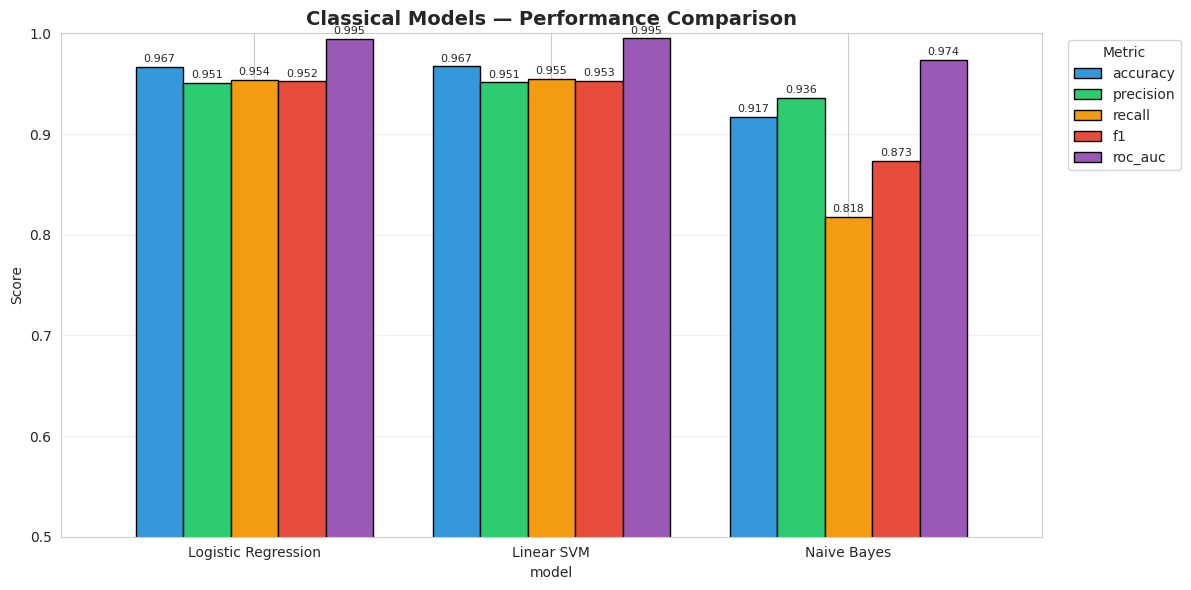

💾 Chart saved


In [ ]:
all_metrics = [lr_metrics, svm_metrics, nb_metrics]
results_df = pd.DataFrame(all_metrics).set_index('model')

print("📊 Comparison Table:")
print(results_df.round(4))

# Bar chart of metrics
fig, ax = plt.subplots(figsize=(12, 6))
results_df[['accuracy', 'precision', 'recall', 'f1', 'roc_auc']].plot(
    kind='bar', ax=ax, edgecolor='black', width=0.8,
    color=['#3498db', '#2ecc71', '#f39c12', '#e74c3c', '#9b59b6'])
ax.set_title('Classical Models — Performance Comparison', fontweight='bold', fontsize=14)
ax.set_ylabel('Score')
ax.set_ylim(0.5, 1.0)
ax.set_xticklabels(results_df.index, rotation=0)
ax.legend(title='Metric', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)

# Add value labels on bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', fontsize=8, padding=2)

plt.tight_layout()
plt.savefig(f'{RESULTS_PATH}/classical_models_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"💾 Chart saved")

## 🎯 Step 9: Confusion Matrices

Confusion matrices show *where* each model is making mistakes. Required by Rubric Step 8.

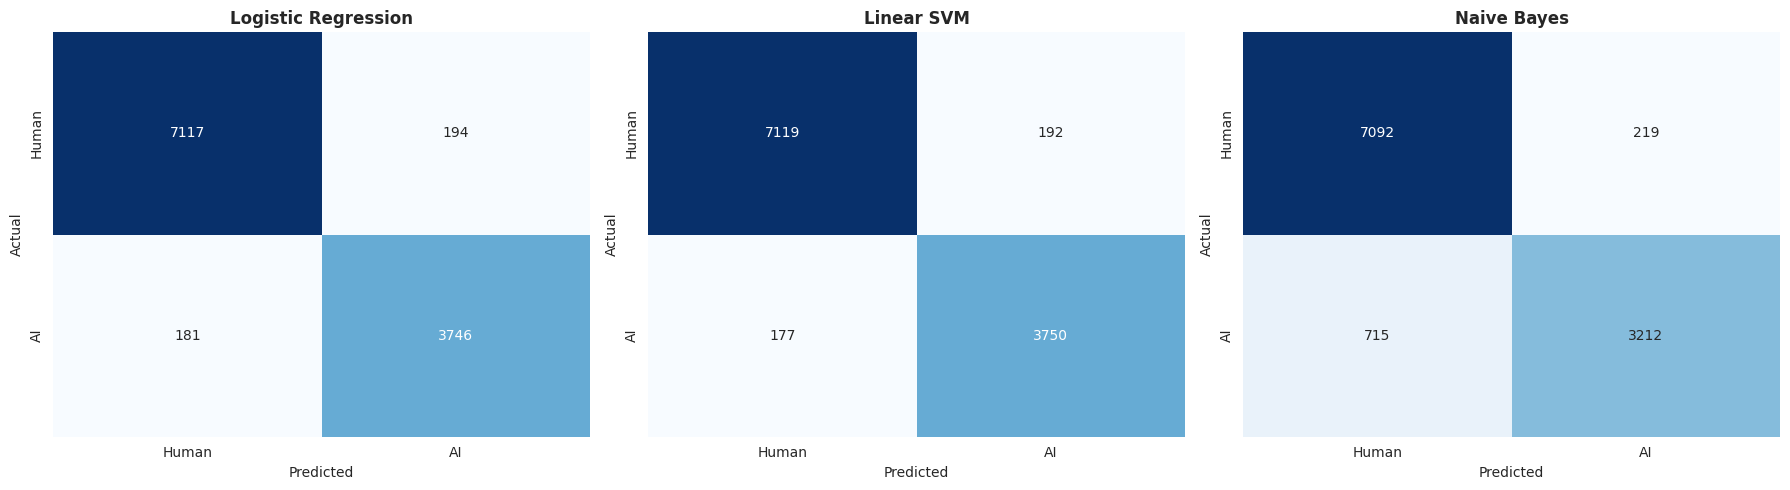

💾 Confusion matrices saved


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, pred) in zip(axes, [
    ('Logistic Regression', lr_pred),
    ('Linear SVM', svm_pred),
    ('Naive Bayes', nb_pred)
]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Human', 'AI'],
                yticklabels=['Human', 'AI'], ax=ax, cbar=False)
    ax.set_title(name, fontweight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.savefig(f'{RESULTS_PATH}/classical_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()
print("💾 Confusion matrices saved")

## 📈 Step 10: ROC Curves

ROC curves show the trade-off between true positive rate and false positive rate. Higher area under curve (AUC) = better discrimination.

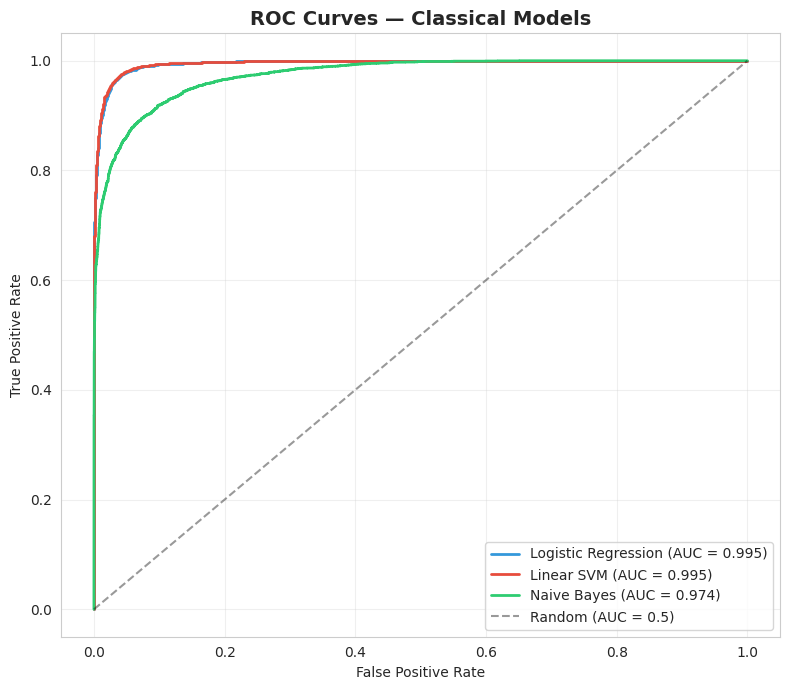

💾 ROC curves saved


In [ ]:
fig, ax = plt.subplots(figsize=(8, 7))

models_for_roc = [
    (lr_best, 'Logistic Regression', lr_metrics['roc_auc'], '#3498db'),
    (svm_best, 'Linear SVM',          svm_metrics['roc_auc'], '#e74c3c'),
    (nb_best, 'Naive Bayes',          nb_metrics['roc_auc'], '#2ecc71'),
]

for model, name, auc, color in models_for_roc:
    if hasattr(model, 'predict_proba'):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)
    fpr, tpr, _ = roc_curve(y_test, y_score)
    ax.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})', linewidth=2, color=color)

ax.plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Random (AUC = 0.5)')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves — Classical Models', fontweight='bold', fontsize=14)
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{RESULTS_PATH}/classical_roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print("💾 ROC curves saved")

## 🔍 Step 11: Quick Error Analysis

Look at examples where the **best classical model** got it wrong. Required by Rubric Step 8 (qualitative evaluation).

📝 **For your report:** Discuss WHY the model fails on these examples. Is it ambiguous text? Domain mismatch? Length issues?

In [ ]:
# Pick the best model by F1
best_idx = np.argmax([lr_metrics['f1'], svm_metrics['f1'], nb_metrics['f1']])
best_pred = [lr_pred, svm_pred, nb_pred][best_idx]
best_name = ['Logistic Regression', 'Linear SVM', 'Naive Bayes'][best_idx]
print(f"🏆 Best classical model: {best_name}")

# Get misclassified examples
wrong_mask = best_pred != y_test
wrong_indices = np.where(wrong_mask)[0]
print(f"❌ Misclassified samples: {wrong_mask.sum()} / {len(y_test)} ({wrong_mask.mean()*100:.2f}%)")

# Show 5 examples of each error type
print("\n" + "="*70)
print("FALSE POSITIVES (Human texts predicted as AI):")
print("="*70)
fp_mask = (best_pred == 1) & (y_test == 0)
for i, idx in enumerate(np.where(fp_mask)[0][:3]):
    print(f"\n[{i+1}] Domain: {test_df.iloc[idx]['domain']}")
    print(f"Text: {test_df.iloc[idx]['text'][:300]}...")

print("\n" + "="*70)
print("FALSE NEGATIVES (AI texts predicted as Human):")
print("="*70)
fn_mask = (best_pred == 0) & (y_test == 1)
for i, idx in enumerate(np.where(fn_mask)[0][:3]):
    print(f"\n[{i+1}] Domain: {test_df.iloc[idx]['domain']}")
    print(f"Text: {test_df.iloc[idx]['text'][:300]}...")

🏆 Best classical model: Linear SVM
❌ Misclassified samples: 369 / 11238 (3.28%)

FALSE POSITIVES (Human texts predicted as AI):

[1] Domain: open_qa
Text: The term "button-down" (which refers a type of shirt which has a collar fastened down by buttons) is sometimes used in error to apply to all shirts (with or without buttoned down collars), being used as a synonym for "button-up" or "button-front"....

[2] Domain: reddit_eli5
Text: In Russia traffic fraud is common . People will hit you on purpose or a pedestrian will deliberately try to get you to hit them so they can sue you . The footage helps get such incidents thrown out of court ....

[3] Domain: open_qa
Text: In some countries, the return address is conventionally located in the upper left hand corner of the envelope , card, or label.In the United Kingdom , the return address is usually placed on the reverse of the envelope, near the top....

FALSE NEGATIVES (AI texts predicted as Human):

[1] Domain: reddit_eli5
Text: Sure! A 

## 🌍 Step 12: BONUS — Cross-Domain Performance Analysis

**This is your differentiator.** Most students stop at overall accuracy. We break it down by domain to see how the model generalizes.

📝 **For your report:** Are some domains harder than others? Why? This is the kind of insight that gets you an A+.

📊 Cross-domain performance (Linear SVM):
        domain  n_samples  accuracy      f1
3     medicine        378    1.0000  1.0000
2      finance       1240    0.9750  0.9770
0  reddit_eli5       8727    0.9720  0.9497
1      open_qa        652    0.9003  0.9367
4    wiki_csai        241    0.8797  0.8863


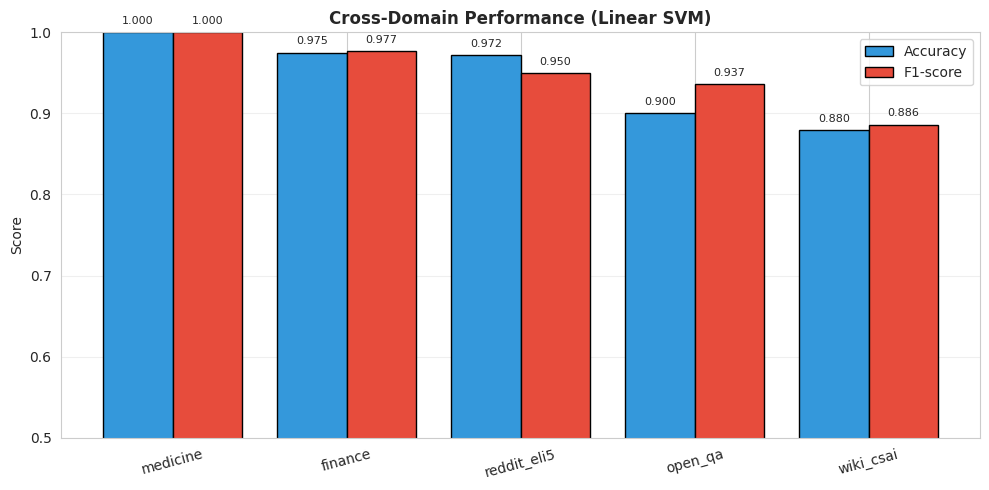

In [ ]:
# Use the best model for the cross-domain analysis
best_model = [lr_best, svm_best, nb_best][best_idx]

domain_results = []
for domain in test_df['domain'].unique():
    mask = test_df['domain'] == domain
    n = mask.sum()
    if n < 10:
        continue
    y_d = y_test[mask.values]
    pred_d = best_pred[mask.values]
    domain_results.append({
        'domain': domain,
        'n_samples': n,
        'accuracy': accuracy_score(y_d, pred_d),
        'f1': f1_score(y_d, pred_d, zero_division=0)
    })

domain_df = pd.DataFrame(domain_results).sort_values('f1', ascending=False)
print(f"📊 Cross-domain performance ({best_name}):")
print(domain_df.round(4))

# Plot
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(domain_df))
ax.bar(x - 0.2, domain_df['accuracy'], 0.4, label='Accuracy', color='#3498db', edgecolor='black')
ax.bar(x + 0.2, domain_df['f1'], 0.4, label='F1-score', color='#e74c3c', edgecolor='black')
ax.set_xticks(x)
ax.set_xticklabels(domain_df['domain'], rotation=15)
ax.set_ylabel('Score')
ax.set_ylim(0.5, 1.0)
ax.set_title(f'Cross-Domain Performance ({best_name})', fontweight='bold')
ax.legend()
ax.grid(axis='y', alpha=0.3)

for i, row in enumerate(domain_df.itertuples()):
    ax.text(i - 0.2, row.accuracy + 0.01, f'{row.accuracy:.3f}', ha='center', fontsize=8)
    ax.text(i + 0.2, row.f1 + 0.01, f'{row.f1:.3f}', ha='center', fontsize=8)

plt.tight_layout()
plt.savefig(f'{RESULTS_PATH}/classical_cross_domain.png', dpi=150, bbox_inches='tight')
plt.show()

## 💾 Step 13: Save All Results to JSON

We save in JSON so Notebook 06 (final comparison) can load all model results in one go.

In [ ]:
results_to_save = {
    'logistic_regression': {**lr_metrics, 'best_params': lr_search.best_params_},
    'linear_svm':          {**svm_metrics, 'best_params': svm_search.best_params_},
    'naive_bayes':         {**nb_metrics, 'best_params': nb_search.best_params_},
    'cross_domain':        domain_df.to_dict('records'),
}

results_file = f'{RESULTS_PATH}/classical_results.json'
with open(results_file, 'w') as f:
    json.dump(results_to_save, f, indent=2, default=str)

print(f"💾 Results saved to {results_file}")

print("\n" + "="*60)
print("📋 NOTEBOOK 03 SUMMARY — FOR YOUR REPORT")
print("="*60)
print(f"Best classical model: {best_name}")
print(f"Best F1-score:        {results_df['f1'].max():.4f}")
print(f"Best Accuracy:        {results_df['accuracy'].max():.4f}")
print(f"Models trained:       3")
print(f"Hyperparameters tuned via 3-fold GridSearchCV")
print(f"Easiest domain to detect: {domain_df.iloc[0]['domain']} (F1={domain_df.iloc[0]['f1']:.3f})")
print(f"Hardest domain to detect: {domain_df.iloc[-1]['domain']} (F1={domain_df.iloc[-1]['f1']:.3f})")

💾 Results saved to /content/drive/MyDrive/ai-text-detection/results/classical_results.json

📋 NOTEBOOK 03 SUMMARY — FOR YOUR REPORT
Best classical model: Linear SVM
Best F1-score:        0.9531
Best Accuracy:        0.9672
Models trained:       3
Hyperparameters tuned via 3-fold GridSearchCV
Easiest domain to detect: medicine (F1=1.000)
Hardest domain to detect: wiki_csai (F1=0.886)


## 📋 Notebook 03 Summary

### What we accomplished:
1. ✅ Built TF-IDF features (20K vocab, unigrams + bigrams)
2. ✅ Trained 3 classical models with GridSearchCV hyperparameter tuning
3. ✅ Computed full metrics: accuracy, precision, recall, F1, ROC AUC
4. ✅ Generated confusion matrices and ROC curves
5. ✅ Performed error analysis (false positives + false negatives)
6. ✅ **Cross-domain analysis** — your differentiator
7. ✅ Saved all models + results for Notebook 06

### Files Generated:
- `models/tfidf_vectorizer.pkl`
- `models/logistic_regression.pkl`
- `models/linear_svm.pkl`
- `models/naive_bayes.pkl`
- `results/classical_results.json` — ALL metrics
- `results/classical_models_comparison.png`
- `results/classical_confusion_matrices.png`
- `results/classical_roc_curves.png`
- `results/classical_cross_domain.png`

### 📝 Key Talking Points for Your Report:
- TF-IDF with bigrams captures stylistic AI patterns ("in conclusion", "it is important")
- Logistic Regression typically wins among classical models for text
- Cross-domain analysis reveals which domains are hardest — likely the casual/short ones
- Classical models are fast and explainable — important when you need to explain AI decisions

### ➡️ Next Step:
**Notebook 04 — Bi-LSTM with GloVe Embeddings (Day 2)**

We'll build our first deep learning model. Make sure GPU is enabled (Runtime → Change runtime type → T4 GPU).